In [ ]:
!pip install transformers datasets accelerate evaluate scikit-learn -q

In [ ]:
import pandas as pd
import numpy as np
import re

from datasets import Dataset

from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
    DataCollatorWithPadding,
    EarlyStoppingCallback
)

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support
)

import torch

In [ ]:
def text_cleaning(text):
    text = str(text).lower()
    text = re.sub(r"http\S+", "", text)
    text = re.sub(r"\n", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

In [ ]:
train_df = pd.read_csv("train.csv")
test_df = pd.read_csv("test.csv")

train_df["reviews_content"] = train_df["reviews_content"].apply(text_cleaning)
test_df["reviews_content"] = test_df["reviews_content"].apply(text_cleaning)

print(train_df.shape)
print(test_df.shape)

train_df.head()

(1500, 2)
(500, 1)


,reviews_content,category
0,airplane ! is considered among many to be the ...,positive
1,you've got to love disney . no matter what the...,positive
2,""" the tailor of panama "" is a different kind o...",positive
3,"the characters in jonathan lynn's "" the whole ...",negative
4,"vikings v . bears ? no , this isn't the lineup...",negative


In [ ]:
label2id = {
    "negative": 0,
    "positive": 1
}

id2label = {
    0: "negative",
    1: "positive"
}

train_df["label"] = train_df["category"].map(label2id)

In [ ]:
train_texts, val_texts, train_labels, val_labels = train_test_split(
    train_df["reviews_content"],
    train_df["label"],
    test_size=0.2,
    random_state=42,
    stratify=train_df["label"]
)

In [ ]:
train_dataset = Dataset.from_pandas(
    pd.DataFrame({
        "reviews_content": train_texts,
        "label": train_labels
    })
)

val_dataset = Dataset.from_pandas(
    pd.DataFrame({
        "reviews_content": val_texts,
        "label": val_labels
    })
)

test_dataset = Dataset.from_pandas(
    pd.DataFrame({
        "reviews_content": test_df["reviews_content"]
    })
)

In [ ]:
MODEL_NAME = "FacebookAI/roberta-large"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

def tokenize_function(examples):
    return tokenizer(
        examples["reviews_content"],
        truncation=True,
        padding="max_length",
        max_length=512
    )

train_dataset = train_dataset.map(tokenize_function, batched=True)
val_dataset = val_dataset.map(tokenize_function, batched=True)
test_dataset = test_dataset.map(tokenize_function, batched=True)

Map:   0%|          | 0/1200 [00:00<?, ? examples/s]

Map:   0%|          | 0/300 [00:00<?, ? examples/s]

Map:   0%|          | 0/500 [00:00<?, ? examples/s]

In [ ]:
data_collator = DataCollatorWithPadding(
    tokenizer=tokenizer
)

In [ ]:
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=2,
    id2label=id2label,
    label2id=label2id
)

Loading weights:   0%|          | 0/389 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: FacebookAI/roberta-large
Key                        | Status     | 
---------------------------+------------+-
lm_head.layer_norm.bias    | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
lm_head.bias               | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
classifier.out_proj.bias   | MISSING    | 
classifier.out_proj.weight | MISSING    | 
classifier.dense.weight    | MISSING    | 
classifier.dense.bias      | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [ ]:
def compute_metrics(eval_pred):

    logits, labels = eval_pred

    preds = np.argmax(logits, axis=1)

    precision, recall, f1, _ = precision_recall_fscore_support(
        labels,
        preds,
        average="binary"
    )

    acc = accuracy_score(labels, preds)

    return {
        "accuracy": acc,
        "precision": precision,
        "recall": recall,
        "f1": f1
    }

In [ ]:
training_args = TrainingArguments(
    output_dir="./roberta-large-sentiment",
    eval_strategy="epoch",
    save_strategy="epoch",
    learning_rate=2e-5, # Reduced learning rate to mitigate FP16 unscaling error
    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,
    num_train_epochs=5,
    weight_decay=0.01,
    warmup_steps=10000,
    load_best_model_at_end=True,
    metric_for_best_model="f1",
    greater_is_better=True,
    save_total_limit=2,
    fp16=torch.cuda.is_available(),
    logging_steps=500,
    report_to="none"
)

In [ ]:
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    data_collator=data_collator,
    compute_metrics=compute_metrics,
    callbacks=[
        EarlyStoppingCallback(
            early_stopping_patience=2
        )
    ]
)

In [ ]:
trainer.train()

Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,No log,0.700897,0.523333,0.600000,0.140000,0.227027
2,No log,0.701875,0.436667,0.441718,0.480000,0.460064
3,No log,0.682257,0.603333,0.678161,0.393333,0.497890
4,0.695775,0.610496,0.733333,0.761194,0.680000,0.718310
5,0.695775,0.188596,0.940000,0.945946,0.933333,0.939597


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=750, training_loss=0.6293887837727865, metrics={'train_runtime': 1130.2848, 'train_samples_per_second': 5.308, 'train_steps_per_second': 0.664, 'total_flos': 5591588179968000.0, 'train_loss': 0.6293887837727865, 'epoch': 5.0})

In [ ]:
results = trainer.evaluate()

print(results)

Training Loss,Validation Loss,Epoch,Accuracy,Precision,Recall,F1
0.695775,0.188596,5,0.940000,0.945946,0.933333,0.939597


{'eval_loss': 0.18859615921974182, 'eval_accuracy': 0.94, 'eval_precision': 0.9459459459459459, 'eval_recall': 0.9333333333333333, 'eval_f1': 0.9395973154362416}


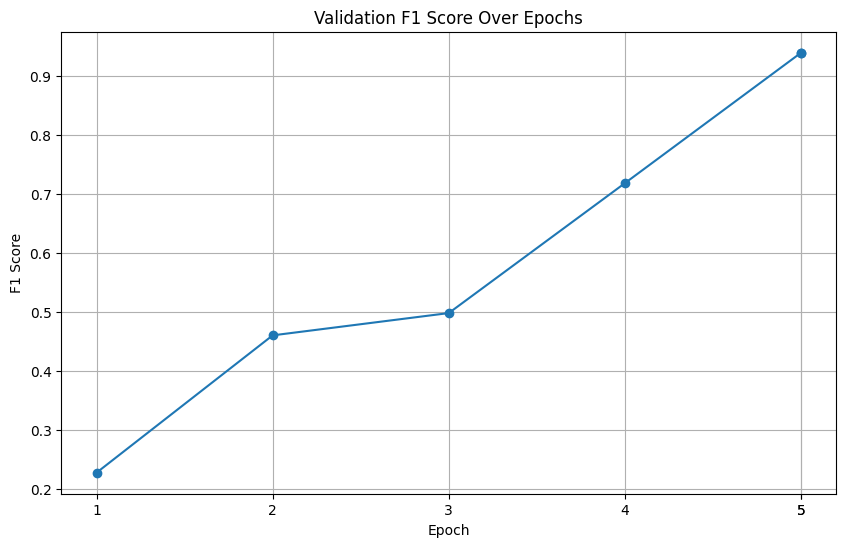

<Figure size 640x480 with 0 Axes>

In [ ]:
import matplotlib.pyplot as plt

# Filter for evaluation logs
eval_logs = [log for log in trainer.state.log_history if 'eval_f1' in log]

# Extract epoch and eval_f1 values
epochs = [log['epoch'] for log in eval_logs]
f1_scores = [log['eval_f1'] for log in eval_logs]

# Plotting the F1 score over epochs
plt.figure(figsize=(10, 6))
plt.plot(epochs, f1_scores, marker='o')
plt.title('Validation F1 Score Over Epochs')
plt.xlabel('Epoch')
plt.ylabel('F1 Score')
plt.grid(True)
plt.xticks(epochs)
plt.show()
plt.savefig("2e-5.png")

In [ ]:
predictions = trainer.predict(test_dataset)

preds = np.argmax(
    predictions.predictions,
    axis=1
)

In [ ]:
pred_labels = [
    id2label[p]
    for p in preds
]

In [ ]:
submission = pd.DataFrame({
    "Row": range(1, len(pred_labels)+1),
    "Label": pred_labels
})

submission.head()

,Row,Label
0,1,positive
1,2,positive
2,3,negative
3,4,positive
4,5,positive


In [ ]:
submission.to_csv(
    "uhuy.csv",
    index=False
)

print("submission.csv saved!")

submission.csv saved!
